# Notebook 1 — EDA & Pembersihan Data
**Kasus 08 · Prediksi Keterlambatan Paket**

Notebook ini:
1. Memuat `data/raw.csv` (40.500 baris)
2. Mengidentifikasi dan menangani masalah kualitas data
3. Menghasilkan grafik EDA utama
4. Menyimpan `data/clean.csv` (40.000 baris) dan `data/tabel_masalah_data.csv`

In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["figure.dpi"] = 100

RAW = "../data/raw.csv"
OUT_CLEAN = "../data/clean.csv"
OUT_TABEL = "../data/tabel_masalah_data.csv"

## 1 · Muat Data Mentah

In [27]:
df = pd.read_csv(RAW)
n_awal = len(df)
print(f"Jumlah baris mentah: {n_awal:,}")
print(f"Jumlah kolom      : {df.shape[1]}")
df.head()

Jumlah baris mentah: 40,500
Jumlah kolom      : 13


,id_resi,tanggal_pickup,jam_pickup,kota_tujuan,jarak_km,jumlah_transit,layanan,janji_hari,berat_kg,metode_bayar,cuaca_saat_pickup,volume_hub_hari,terlambat
0,BDG69958899,2025-01-01,14,Tasikmalaya,109.0,2,HEMAT,4,5.93,COD,berawan,4990,0
1,BDG98718051,2025-01-01,15,Surabaya,678.0,2,HEMAT,5,0.78,non_COD,berawan,4769,0
2,BDG40074637,2025-01-01,14,Bekasi,128.0,1,REG,2,2.57,COD,cerah,4286,0
3,BDG00168612,2025-01-01,14,Pontianak,885.0,3,REG,3,1.12,COD,cerah,4856,1
4,BDG72495951,2025-01-01,12,Denpasar,1057.0,3,EXPRESS,3,1.68,non_COD,berawan,5467,0


In [28]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 40500 entries, 0 to 40499
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id_resi            40500 non-null  str    
 1   tanggal_pickup     40500 non-null  str    
 2   jam_pickup         40500 non-null  int64  
 3   kota_tujuan        40500 non-null  str    
 4   jarak_km           39687 non-null  float64
 5   jumlah_transit     40500 non-null  int64  
 6   layanan            40500 non-null  str    
 7   janji_hari         40500 non-null  int64  
 8   berat_kg           40500 non-null  float64
 9   metode_bayar       40500 non-null  str    
 10  cuaca_saat_pickup  40094 non-null  str    
 11  volume_hub_hari    40500 non-null  int64  
 12  terlambat          40500 non-null  int64  
dtypes: float64(2), int64(5), str(6)
memory usage: 5.7 MB


In [29]:
df.describe()

,jam_pickup,jarak_km,jumlah_transit,janji_hari,berat_kg,volume_hub_hari,terlambat
count,40500.000000,39687.000000,40500.000000,40500.000000,40500.000000,40500.000000,40500.000000
mean,13.557481,533.669766,2.086914,2.895012,61.987259,5738.810148,0.177926
std,3.398354,516.938576,1.134676,1.233995,530.144246,1681.086632,0.382455
min,7.000000,90.000000,1.000000,1.000000,-1.000000,2861.000000,0.000000
25%,11.000000,135.000000,1.000000,2.000000,0.740000,4892.000000,0.000000
50%,14.000000,356.000000,2.000000,3.000000,1.380000,5358.000000,0.000000
75%,16.000000,782.000000,3.000000,4.000000,2.640000,5916.000000,0.000000
max,22.000000,2194.000000,5.000000,6.000000,28310.000000,17979.000000,1.000000


In [30]:
# Daftar pencatat masalah data untuk tabel laporan
masalah = []

def catat(jenis, jumlah, cara, alasan):
    masalah.append({
        "Masalah": jenis,
        "Jumlah baris": int(jumlah),
        "Cara menangani": cara,
        "Alasan": alasan,
    })

## 2 · Pembersihan Data

### 2.1 Hapus duplikat penuh (`id_resi` sama)

In [31]:
n_dup = df.duplicated().sum()
print(f"Duplikat penuh ditemukan: {n_dup}")

df = df.drop_duplicates().reset_index(drop=True)
assert df.id_resi.is_unique, "Masih ada id_resi duplikat!"

catat("Baris duplikat penuh", n_dup, "drop_duplicates",
      "Satu resi hanya boleh muncul sekali; duplikat membuat paket terhitung ganda.")
print(f"Sisa baris setelah hapus duplikat: {len(df):,}")

Duplikat penuh ditemukan: 500
Sisa baris setelah hapus duplikat: 40,000


### 2.2 Konversi tanggal

In [32]:
df["tanggal_pickup"] = pd.to_datetime(df["tanggal_pickup"])
print(f"Rentang tanggal: {df['tanggal_pickup'].min().date()} s.d. {df['tanggal_pickup'].max().date()}")

Rentang tanggal: 2025-01-01 s.d. 2026-06-30


### 2.3 Standarisasi kolom `layanan`

In [33]:
print("Nilai unik layanan sebelum standarisasi:")
print(df["layanan"].value_counts())

Nilai unik layanan sebelum standarisasi:
layanan
REG        23381
EXPRESS     7910
HEMAT       7909
EXP          211
Express      209
hemat        209
reg          171
Name: count, dtype: int64


In [34]:
peta_layanan = {
    "EXP": "EXPRESS", "EXPRESS": "EXPRESS",
    "REG": "REG",
    "HEMAT": "HEMAT",
}
lay_baru = df["layanan"].str.strip().str.upper().map(peta_layanan)
assert lay_baru.notna().all(), f"Ada nilai tak terpeta: {df.loc[lay_baru.isna(), 'layanan'].unique()}"

n_layanan_berubah = (df["layanan"] != lay_baru).sum()
catat("Penulisan layanan tidak konsisten (Express, EXP, hemat, reg)",
      n_layanan_berubah, "Ubah ke 3 nilai baku: EXPRESS, REG, HEMAT",
      "Varian ejaan dianggap kategori berbeda oleh model.")
df["layanan"] = lay_baru

print(f"\nBaris yang dikoreksi: {n_layanan_berubah}")
print("Nilai unik layanan setelah standarisasi:")
print(df["layanan"].value_counts())


Baris yang dikoreksi: 800
Nilai unik layanan setelah standarisasi:
layanan
REG        23552
EXPRESS     8330
HEMAT       8118
Name: count, dtype: int64


### 2.4 Standarisasi kolom `kota_tujuan` (28 varian → 15 kota)

In [35]:
print("Nilai unik kota tujuan sebelum standarisasi:")
print(df["kota_tujuan"].value_counts().to_string())

Nilai unik kota tujuan sebelum standarisasi:
kota_tujuan
Jakarta          7601
Bekasi           3775
Surabaya         3316
Bogor            3211
Semarang         2751
Yogyakarta       2648
Tasikmalaya      2067
Cirebon          1994
Denpasar         1898
Medan            1883
Malang           1695
Makassar         1618
Balikpapan       1587
Palembang        1586
Pontianak        1238
jakarta           139
Jkt               136
bekasi            133
DKI Jakarta       120
Kota Bekasi       108
surabaya           97
Sby                88
MEDAN              74
DI Yogyakarta      60
Jogja              51
Bali               46
denpasar           45
Yogya              35


In [36]:
peta_kota = {
    "jakarta": "Jakarta", "dki jakarta": "Jakarta", "jkt": "Jakarta",
    "bekasi": "Bekasi", "kota bekasi": "Bekasi",
    "surabaya": "Surabaya", "sby": "Surabaya",
    "medan": "Medan",
    "yogyakarta": "Yogyakarta", "di yogyakarta": "Yogyakarta",
    "jogja": "Yogyakarta", "yogya": "Yogyakarta",
    "denpasar": "Denpasar", "bali": "Denpasar",  # Keputusan tim: Bali dipetakan ke Denpasar
    "bogor": "Bogor", "semarang": "Semarang", "tasikmalaya": "Tasikmalaya",
    "cirebon": "Cirebon", "malang": "Malang", "makassar": "Makassar",
    "palembang": "Palembang", "balikpapan": "Balikpapan", "pontianak": "Pontianak",
}
kota_baru = df["kota_tujuan"].str.strip().str.lower().map(peta_kota)
assert kota_baru.notna().all(), f"Kota tak terpeta: {df.loc[kota_baru.isna(), 'kota_tujuan'].unique()}"

n_kota_berubah = (df["kota_tujuan"] != kota_baru).sum()
catat("Nama kota tidak baku (Jakarta/Jkt/Sby/Jogja/Bali ...)",
      n_kota_berubah, "Pemetaan manual 28 varian → 15 kota",
      "Kota yang sama tercatat sebagai kategori berbeda; 'Bali' = Denpasar (keputusan tim).")
df["kota_tujuan"] = kota_baru

print(f"\nBaris yang dikoreksi: {n_kota_berubah}")
print(f"Jumlah kota unik: {df['kota_tujuan'].nunique()}")
print(df["kota_tujuan"].value_counts())


Baris yang dikoreksi: 1132
Jumlah kota unik: 15
kota_tujuan
Jakarta        7996
Bekasi         4016
Surabaya       3501
Bogor          3211
Yogyakarta     2794
Semarang       2751
Tasikmalaya    2067
Cirebon        1994
Denpasar       1989
Medan          1957
Malang         1695
Makassar       1618
Balikpapan     1587
Palembang      1586
Pontianak      1238
Name: count, dtype: int64


### 2.5 Perbaikan `berat_kg`: sentinel -1 dan satuan gram

In [37]:
print("Statistik berat_kg sebelum perbaikan:")
print(df["berat_kg"].describe())
print(f"\nBaris dengan berat <= 0 : {(df['berat_kg'] <= 0).sum()}")
print(f"Baris dengan berat >= 100: {(df['berat_kg'] >= 100).sum()}")

Statistik berat_kg sebelum perbaikan:
count    40000.000000
mean        62.192717
std        531.726520
min         -1.000000
25%          0.740000
50%          1.380000
75%          2.640000
max      28310.000000
Name: berat_kg, dtype: float64

Baris dengan berat <= 0 : 80
Baris dengan berat >= 100: 1197


In [38]:
n_neg = (df["berat_kg"] <= 0).sum()
n_gram = (df["berat_kg"] >= 100).sum()

# Keputusan tim: nilai >= 100 tercatat dalam satuan gram, dibagi 1000 menjadi kg
df.loc[df["berat_kg"] >= 100, "berat_kg"] = df["berat_kg"] / 1000
# Keputusan tim: nilai -1 adalah kode kosong, ganti NaN
df.loc[df["berat_kg"] <= 0, "berat_kg"] = np.nan

catat("berat_kg bernilai -1 (kode kosong)", n_neg,
      "Ganti NaN → isi median per layanan",
      "Berat negatif mustahil.")
catat("berat_kg >= 100 (satuan gram)", n_gram,
      "Bagi 1000",
      "Nilai tersebut dalam satuan gram (keputusan tim); setelah konversi sebarannya normal.")

# Imputasi dengan median per layanan (untuk EDA saja; di modeling pakai Pipeline)
df["berat_kg"] = df["berat_kg"].fillna(
    df.groupby("layanan")["berat_kg"].transform("median")
)

print("Statistik berat_kg setelah perbaikan:")
print(df["berat_kg"].describe())

Statistik berat_kg setelah perbaikan:
count    40000.000000
mean         2.025866
std          2.291116
min          0.100000
25%          0.730000
50%          1.330000
75%          2.460000
max         44.060000
Name: berat_kg, dtype: float64


### 2.6 Imputasi `jarak_km` kosong → median per kota

In [39]:
n_jarak = df["jarak_km"].isna().sum()
print(f"jarak_km kosong: {n_jarak}")

df["jarak_km"] = df["jarak_km"].fillna(
    df.groupby("kota_tujuan")["jarak_km"].transform("median")
)
catat("jarak_km kosong", n_jarak,
      "Isi median jarak per kota tujuan",
      "Jarak ditentukan oleh kota tujuan, jadi median per kota perkiraan yang baik.")

assert df["jarak_km"].notna().all()
print("Semua jarak_km sudah terisi.")

jarak_km kosong: 800
Semua jarak_km sudah terisi.


### 2.7 Imputasi `cuaca_saat_pickup` kosong → 'tidak_diketahui'

In [40]:
n_cuaca = df["cuaca_saat_pickup"].isna().sum()
print(f"cuaca_saat_pickup kosong: {n_cuaca}")

df["cuaca_saat_pickup"] = df["cuaca_saat_pickup"].fillna("tidak_diketahui")
catat("cuaca_saat_pickup kosong", n_cuaca,
      "Isi kategori 'tidak_diketahui'",
      "Aplikasi nyata juga bisa tidak punya data cuaca; model belajar menanganinya.")

print("Distribusi cuaca:")
print(df["cuaca_saat_pickup"].value_counts())

cuaca_saat_pickup kosong: 400
Distribusi cuaca:
cuaca_saat_pickup
cerah              15912
berawan            11845
hujan               7932
hujan_lebat         3911
tidak_diketahui      400
Name: count, dtype: int64


### 2.8 Pemeriksaan tambahan (tidak diubah, hanya dicatat)

In [41]:
# Kombinasi layanan vs janji_hari
print("Crosstab layanan × janji_hari:")
ct = pd.crosstab(df["layanan"], df["janji_hari"])
print(ct)
print(f"\nKombinasi langka (< 100 baris) yang bisa merupakan inkonsistensi entri:")
for lay in ct.index:
    for hari in ct.columns:
        val = ct.loc[lay, hari]
        if 0 < val < 100:
            print(f"  {lay} × {hari} hari: {val} baris")

Crosstab layanan × janji_hari:
janji_hari     1      2     3     4     5     6
layanan                                        
EXPRESS     3845   2856  1513    78    23    15
HEMAT         16     69    51  3877  2752  1353
REG           18  11336  8014  4172    10     2

Kombinasi langka (< 100 baris) yang bisa merupakan inkonsistensi entri:
  EXPRESS × 4 hari: 78 baris
  EXPRESS × 5 hari: 23 baris
  EXPRESS × 6 hari: 15 baris
  HEMAT × 1 hari: 16 baris
  HEMAT × 2 hari: 69 baris
  HEMAT × 3 hari: 51 baris
  REG × 1 hari: 18 baris
  REG × 5 hari: 10 baris
  REG × 6 hari: 2 baris


In [42]:
# Volume hub bervariasi dalam hari yang sama
vol = df.groupby("tanggal_pickup")["volume_hub_hari"].agg(["min", "max"])
rasio_vol = (vol["max"] / vol["min"]).mean()
print(f"volume_hub_hari berbeda-beda pada hari yang sama.")
print(f"Rasio max/min rata-rata: {rasio_vol:.2f}")
print("Temuan: volume_hub_hari bervariasi per pencatatan, bukan per hari. Dibiarkan apa adanya.")

volume_hub_hari berbeda-beda pada hari yang sama.
Rasio max/min rata-rata: 1.78
Temuan: volume_hub_hari bervariasi per pencatatan, bukan per hari. Dibiarkan apa adanya.


### 2.9 Ringkasan pembersihan

In [43]:
print(f"\n{'='*60}")
print(f"RINGKASAN: {n_awal:,} baris mentah → {len(df):,} baris bersih")
print(f"{'='*60}")

tabel = pd.DataFrame(masalah)
tabel


RINGKASAN: 40,500 baris mentah → 40,000 baris bersih


,Masalah,Jumlah baris,Cara menangani,Alasan
0,Baris duplikat penuh,500,drop_duplicates,Satu resi hanya boleh muncul sekali; duplikat ...
1,"Penulisan layanan tidak konsisten (Express, EX...",800,"Ubah ke 3 nilai baku: EXPRESS, REG, HEMAT",Varian ejaan dianggap kategori berbeda oleh mo...
2,Nama kota tidak baku (Jakarta/Jkt/Sby/Jogja/Ba...,1132,Pemetaan manual 28 varian → 15 kota,Kota yang sama tercatat sebagai kategori berbe...
3,berat_kg bernilai -1 (kode kosong),80,Ganti NaN → isi median per layanan,Berat negatif mustahil.
4,berat_kg >= 100 (satuan gram),1197,Bagi 1000,Nilai tersebut dalam satuan gram (keputusan ti...
5,jarak_km kosong,800,Isi median jarak per kota tujuan,"Jarak ditentukan oleh kota tujuan, jadi median..."
6,cuaca_saat_pickup kosong,400,Isi kategori 'tidak_diketahui',Aplikasi nyata juga bisa tidak punya data cuac...


## 3 · Simpan Data Bersih

In [44]:
df = df.sort_values(["tanggal_pickup", "jam_pickup"]).reset_index(drop=True)
df.to_csv(OUT_CLEAN, index=False)
tabel.to_csv(OUT_TABEL, index=False)
print(f"Data bersih disimpan ke {OUT_CLEAN}")
print(f"Tabel masalah disimpan ke {OUT_TABEL}")

Data bersih disimpan ke ../data/clean.csv
Tabel masalah disimpan ke ../data/tabel_masalah_data.csv


## 4 · Pembagian Data berdasarkan Waktu (Pratinjau)

In [45]:
t = df["tanggal_pickup"]
bagian = np.select(
    [t < "2026-01-01", t < "2026-04-01"],
    ["train", "validation"],
    default="test"
)
print("Ukuran dan rasio terlambat per bagian:")
ringkasan = df.assign(bagian=bagian).groupby("bagian")["terlambat"].agg(["size", "mean"])
ringkasan.columns = ["Jumlah baris", "Rasio terlambat"]
ringkasan["Rasio terlambat"] = ringkasan["Rasio terlambat"].map("{:.1%}".format)
ringkasan

Ukuran dan rasio terlambat per bagian:


,Jumlah baris,Rasio terlambat
bagian,,
test,6744,13.9%
train,26633,17.8%
validation,6623,21.9%


## 5 · EDA — Grafik Utama

### 5.1 Keterlambatan per Bulan

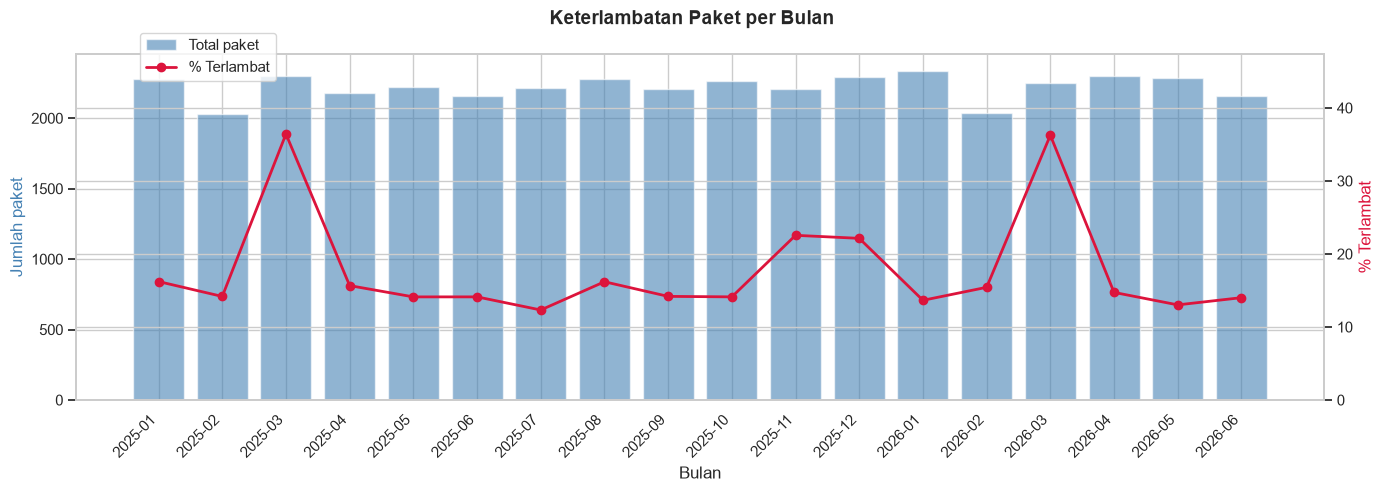

In [46]:
df["bulan_tahun"] = df["tanggal_pickup"].dt.to_period("M")

bulanan = df.groupby("bulan_tahun")["terlambat"].agg(["sum", "count", "mean"])
bulanan.columns = ["jumlah_terlambat", "total", "rasio_terlambat"]

fig, ax1 = plt.subplots(figsize=(14, 5))
x = range(len(bulanan))
labels = [str(p) for p in bulanan.index]

bar = ax1.bar(x, bulanan["total"], color="steelblue", alpha=0.6, label="Total paket")
ax1.set_ylabel("Jumlah paket", color="steelblue")
ax1.set_xlabel("Bulan")
ax1.set_xticks(x)
ax1.set_xticklabels(labels, rotation=45, ha="right")

ax2 = ax1.twinx()
ax2.plot(x, bulanan["rasio_terlambat"] * 100, color="crimson",
         marker="o", linewidth=2, label="% Terlambat")
ax2.set_ylabel("% Terlambat", color="crimson")
ax2.set_ylim(0, bulanan["rasio_terlambat"].max() * 100 * 1.3)

fig.suptitle("Keterlambatan Paket per Bulan", fontsize=14, fontweight="bold")
fig.legend(loc="upper left", bbox_to_anchor=(0.1, 0.95))
plt.tight_layout()
plt.savefig("../artifacts/grafik_terlambat_per_bulan.png", dpi=150, bbox_inches="tight")
plt.show()

### 5.2 Keterlambatan per Jam Pickup

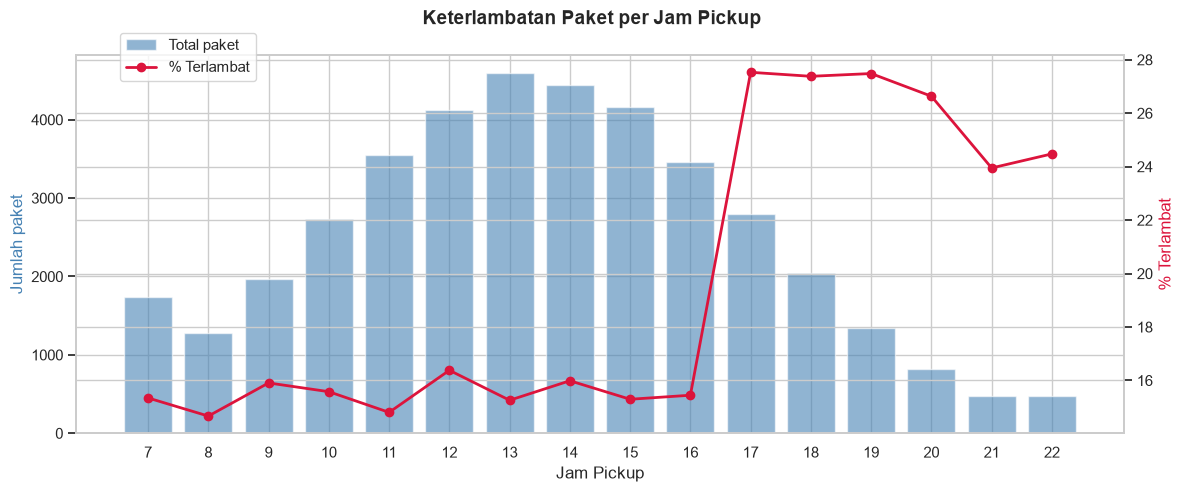

In [47]:
per_jam = df.groupby("jam_pickup")["terlambat"].agg(["sum", "count", "mean"])
per_jam.columns = ["jumlah_terlambat", "total", "rasio_terlambat"]

fig, ax1 = plt.subplots(figsize=(12, 5))
x = per_jam.index

ax1.bar(x, per_jam["total"], color="steelblue", alpha=0.6, label="Total paket")
ax1.set_ylabel("Jumlah paket", color="steelblue")
ax1.set_xlabel("Jam Pickup")
ax1.set_xticks(x)

ax2 = ax1.twinx()
ax2.plot(x, per_jam["rasio_terlambat"] * 100, color="crimson",
         marker="o", linewidth=2, label="% Terlambat")
ax2.set_ylabel("% Terlambat", color="crimson")

fig.suptitle("Keterlambatan Paket per Jam Pickup", fontsize=14, fontweight="bold")
fig.legend(loc="upper left", bbox_to_anchor=(0.1, 0.95))
plt.tight_layout()
plt.savefig("../artifacts/grafik_terlambat_per_jam.png", dpi=150, bbox_inches="tight")
plt.show()

### 5.3 Keterlambatan per Jumlah Transit

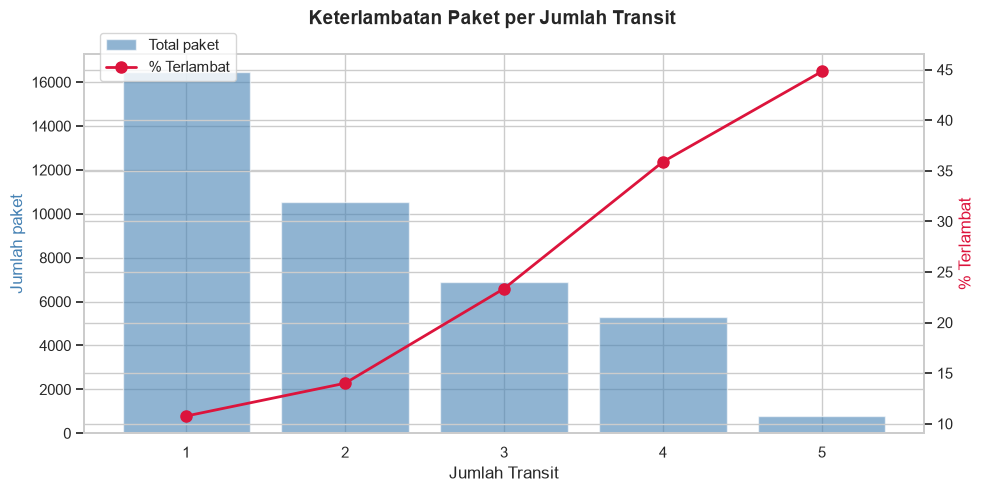

In [48]:
per_transit = df.groupby("jumlah_transit")["terlambat"].agg(["sum", "count", "mean"])
per_transit.columns = ["jumlah_terlambat", "total", "rasio_terlambat"]

fig, ax1 = plt.subplots(figsize=(10, 5))
x = per_transit.index

ax1.bar(x, per_transit["total"], color="steelblue", alpha=0.6, label="Total paket")
ax1.set_ylabel("Jumlah paket", color="steelblue")
ax1.set_xlabel("Jumlah Transit")
ax1.set_xticks(x)

ax2 = ax1.twinx()
ax2.plot(x, per_transit["rasio_terlambat"] * 100, color="crimson",
         marker="o", linewidth=2, markersize=8, label="% Terlambat")
ax2.set_ylabel("% Terlambat", color="crimson")

fig.suptitle("Keterlambatan Paket per Jumlah Transit", fontsize=14, fontweight="bold")
fig.legend(loc="upper left", bbox_to_anchor=(0.1, 0.95))
plt.tight_layout()
plt.savefig("../artifacts/grafik_terlambat_per_transit.png", dpi=150, bbox_inches="tight")
plt.show()

### 5.4 Distribusi Target

Distribusi kolom target (terlambat):
terlambat
0    32877
1     7123
Name: count, dtype: int64

Rasio kelas positif: 17.8%


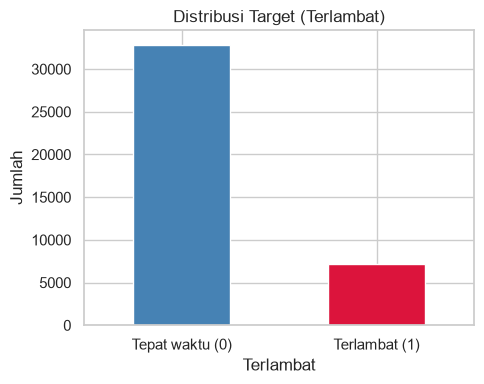

In [49]:
print("Distribusi kolom target (terlambat):")
print(df["terlambat"].value_counts())
print(f"\nRasio kelas positif: {df['terlambat'].mean():.1%}")

fig, ax = plt.subplots(figsize=(5, 4))
df["terlambat"].value_counts().plot.bar(ax=ax, color=["steelblue", "crimson"])
ax.set_title("Distribusi Target (Terlambat)")
ax.set_xlabel("Terlambat")
ax.set_ylabel("Jumlah")
ax.set_xticklabels(["Tepat waktu (0)", "Terlambat (1)"], rotation=0)
plt.tight_layout()
plt.show()

## 6 · Ringkasan Temuan EDA

**Temuan utama:**
1. **Bulan puncak keterlambatan:** Maret 2025 dan November–Desember 2025 menunjukkan lonjakan rasio keterlambatan.
2. **Jam pickup sore (≥17):** Paket yang dijemput sore hari cenderung lebih sering terlambat.
3. **Jumlah transit tinggi:** Semakin banyak transit, semakin tinggi kemungkinan terlambat.
4. **Kelas tidak seimbang:** Sekitar 18% paket terlambat — perlu diperhatikan saat pemilihan metrik.

**Catatan data yang tidak diubah:**
- `volume_hub_hari` bervariasi pada hari yang sama (mungkin per batch pencatatan).
- Sebagian kecil kombinasi `layanan` × `janji_hari` tampak janggal (~285 baris) tetapi dibiarkan apa adanya.

In [50]:
# Bersihkan kolom sementara
df = df.drop(columns=["bulan_tahun"], errors="ignore")
print("Notebook 1 selesai.")
print(f"Data bersih: {OUT_CLEAN} ({len(df):,} baris)")
print(f"Tabel masalah: {OUT_TABEL}")

Notebook 1 selesai.
Data bersih: ../data/clean.csv (40,000 baris)
Tabel masalah: ../data/tabel_masalah_data.csv
